# Ánalise de Vendas de Videogames da loja Ice
EDA de vendas de videogames da loja Ice para identificar quais fatores estão relacionados ao sucesso de um jogo. Comparando plataformas, gêneros, regiões, avaliações de usuários e especialistas, além de observar tendências ao longo dos anos. O objetivo é encontrar padrões que ajudem a prever jogos com maior potencial de vendas e orientar o planejamento de campanhas publicitárias.

# Dicionário de Dados



'games.csv': cada linha corresponde a um jogo lançado em uma determinada plataforma

'Name': é o nome do jogo

'Platform': é a plataforma em que o jogo foi lançado, como Xbox, PlayStation ou Nintendo

'Year_of_Release': é o ano em que o jogo foi lançado

'Genre': é o gênero do jogo, como ação, esporte, corrida ou aventura

'NA_sales': representa as vendas do jogo na América do Norte, em milhões de dólares

'EU_sales': representa as vendas do jogo na Europa, em milhões de dólares

'JP_sales': representa as vendas do jogo no Japão, em milhões de dólares

'Other_sales': representa as vendas do jogo em outras regiões, em milhões de dólares

'Critic_Score': é a pontuação atribuída por críticos especializados, com valor máximo de 100

'User_Score': é a pontuação atribuída pelos usuários, com valor máximo de 10

'Rating': é a classificação indicativa do jogo segundo o sistema ESRB, que informa a faixa etária recomendada para o público.





# Visão e Análise  Geral dos Dados 
Nesta etapa, vou importar o conjunto de dados e realizar uma inspeção inicial da tabela. Serão analisadas a quantidade de linhas e colunas, os tipos de dados, os valores ausentes, os registros duplicados e possíveis inconsistências que precisam ser tratadas antes da análise exploratória.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statistics import mode, StatisticsError
from scipy import stats
from math import comb
from scipy.stats import norm, ttest_1samp, ttest_ind, ttest_rel, levene

In [2]:
games = pd.read_csv('/datasets/games.csv')
#vendo dados iniciais do data 
print(games.describe())
print()
print(games.info())
print()
games.head()



       Year_of_Release      NA_sales      EU_sales      JP_sales  \
count     16446.000000  16715.000000  16715.000000  16715.000000   
mean       2006.484616      0.263377      0.145060      0.077617   
std           5.877050      0.813604      0.503339      0.308853   
min        1980.000000      0.000000      0.000000      0.000000   
25%        2003.000000      0.000000      0.000000      0.000000   
50%        2007.000000      0.080000      0.020000      0.000000   
75%        2010.000000      0.240000      0.110000      0.040000   
max        2016.000000     41.360000     28.960000     10.220000   

        Other_sales  Critic_Score  
count  16715.000000   8137.000000  
mean       0.047342     68.967679  
std        0.186731     13.938165  
min        0.000000     13.000000  
25%        0.000000     60.000000  
50%        0.010000     71.000000  
75%        0.030000     79.000000  
max       10.570000     98.000000  

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entrie

,Name,Platform,Year_of_Release,Genre,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score,User_Score,Rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN


# PREPARAÇÃO DOS DADOS 
<b>TRANSFORMANDO OS NOMES DA COLUNA PARA LETRAS MINUSCULAS</b> 
<b> ANALISANDO VALORES DUPLICADOS </b>


In [3]:
games.columns = games.columns.str.lower()
print(games.columns)
games.duplicated().sum()

Index(['name', 'platform', 'year_of_release', 'genre', 'na_sales', 'eu_sales',
       'jp_sales', 'other_sales', 'critic_score', 'user_score', 'rating'],
      dtype='object')


0

<b> ANALISANDO DADOS E ALTERANDO TIPOS DE DADOS NO DATA</b>


In [4]:
#Transformando os numeros Nan da coluna year em Moda
#Transformando a colunas 'years_of_release' em numeros inteiros

games['year_of_release'] = (
    games['year_of_release']
    .fillna(games['year_of_release'].mode()[0])
    .astype(int)
)
#Transformando a coluna 'user_score' em float 
#Transformando os nomes 'tbd' em Nan
games['user_score'] = (
    games['user_score']
    .replace('tbd', np.nan)
    .astype(float)
)
#Substituindo os valor ausentes na coluna 'Rating' em unknown  
games['rating'] = games['rating'].fillna('unknown')
#Analisando o data frame depois da limpeza
games.head()


,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76.0,8.0,E
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,NaN,NaN,unknown
2,Mario Kart Wii,Wii,2008,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009,Sports,15.61,10.93,3.28,2.95,80.0,8.0,E
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,unknown


# Total de vendas por regiões 

In [5]:
colunas_vendas = ['na_sales', 'eu_sales', 'jp_sales', 'other_sales']

games['total_sales'] = games[colunas_vendas].sum(axis=1)
games.head()

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,total_sales
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76.0,8.0,E,82.54
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,NaN,NaN,unknown,40.24
2,Mario Kart Wii,Wii,2008,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E,35.52
3,Wii Sports Resort,Wii,2009,Sports,15.61,10.93,3.28,2.95,80.0,8.0,E,32.77
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,unknown,31.38


# Mudanças nas Colunas 
Na coluna <b> year_of_release</b> transformei ela de float para inteiro, usando os numeros nulos e substituindo eles pela moda, ou seja pelo valor que aparece com maior frequencia , pois se usarmos a média poderia ter numeros float e não faz sentido nas categórias de ano. 

Na coluna <b> user_score </b> eu transformei os numeros inteiros em numeros float, por que quando precisariamos fazer algum calculo com outros numeros floats em outras colunas, poderia dar muita alteração de resultado pois os numeros float em questão de score são importantes, podendo alterar resultados. Como os numeros Nan tinha alguns str escridas numero 'tbd' junto com os valores transformei em NaN, pois os numeros Nulos era muito alto, se eu fosse fazer a média como dia poucos resultados preenchidos com o numero inteiro de linhas, poderia alterar muito o resultado. Deixando assim todos as usuários que preencheram com 'tbd' também com NaN.

Na coluna <b> rating </b> como não se tratava de numeros e sim de categorias, não faria sentido eu transformar as str em numeros e tentar colocar os numeros Nulos como zero, então preenchi com Unknown querendo dizer que não foi preenchido.


# Analise dos Dados  
<b>Nesta etapa vou:</b>

- Analisar quantos jogos foram lançados por ano no periodo de 1980 a 2016.

- Escolher as Plataformas com maiores vendas totais e a distribuição de cada ano.

- Quanto Tempo leva para as plataformas antigas desaparecereme  as novas aparecerem.

- Quais plataformas estão liderando vendas.

- Quais estão crescendo e quais estão diminuindo.

- Ver as vendas globais de todos os jogos divididos por plataforma e as vendas médias por várias plataformas. 

- Analisar se avaliações de usuários e profissionais afetam nas vendas de uma das plataformas. 

- Comparar vendas dos mesmos jogos em várias plataformas.

- Quais são gêneros mais lucrativos.

# Gráfico de Jogos Lançados a cada Ano

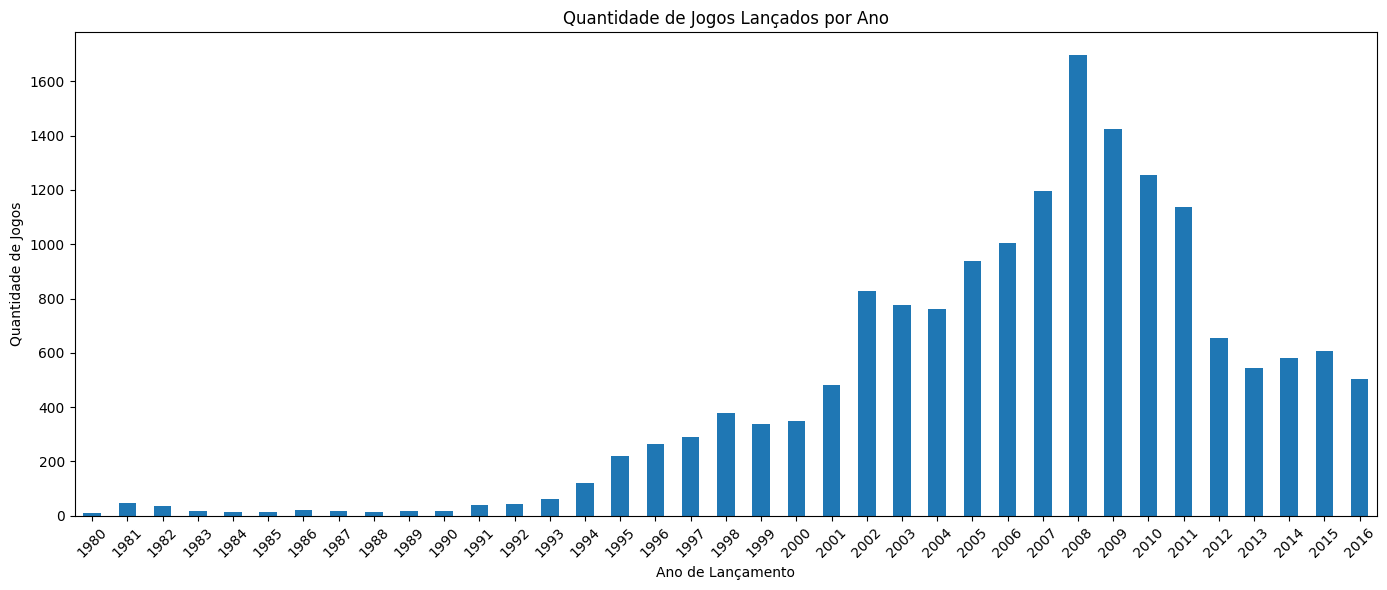

In [6]:
#Vendo quantos jogos foram lançados a cada ano 

jogos_por_ano = (
    games['year_of_release']
        .value_counts()
        .sort_index()

        .plot(
    kind='bar',
    figsize=(14, 6)
))

plt.title('Quantidade de Jogos Lançados por Ano')
plt.xlabel('Ano de Lançamento')

plt.ylabel('Quantidade de Jogos')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Gráfico de Vendas dos Jogos lançados a cada ano

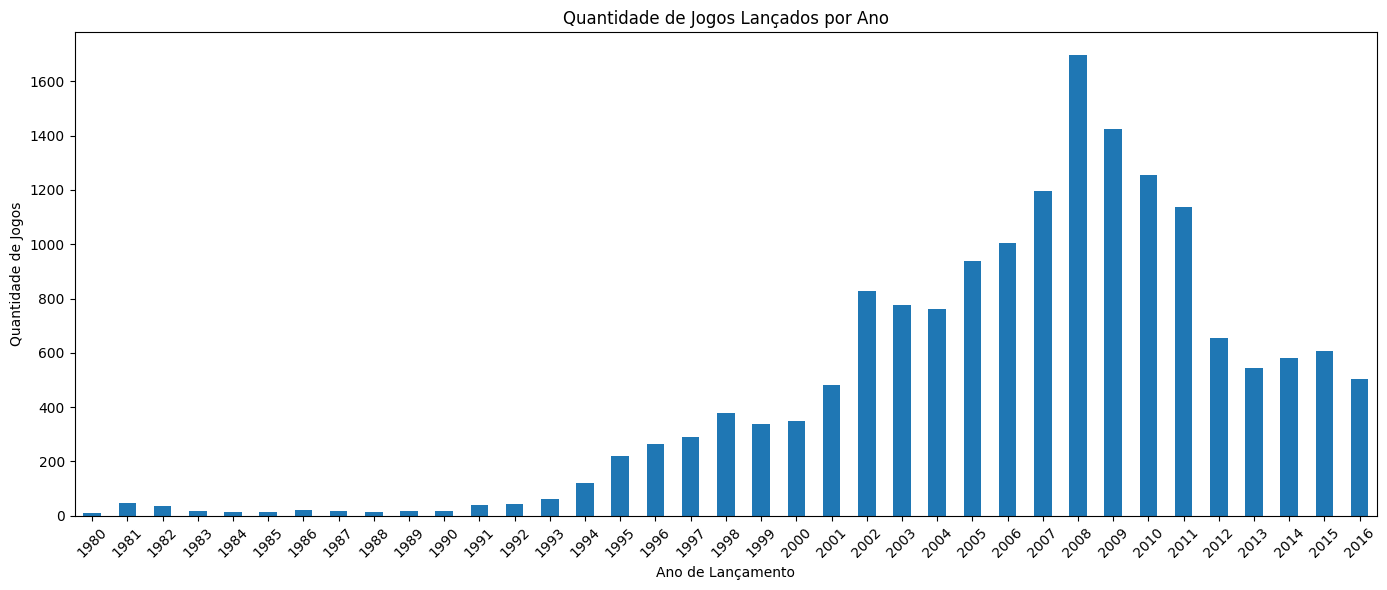

In [7]:
#Vendo quantos jogos foram lançados a cada ano 
jogos_por_ano = (
    games['year_of_release']
        .value_counts()
        .sort_index()
        .plot(
    kind='bar',
    figsize=(14, 6)
))

plt.title('Quantidade de Jogos Lançados por Ano')
plt.xlabel('Ano de Lançamento')

plt.ylabel('Quantidade de Jogos')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Maiores Plataformas de vendas

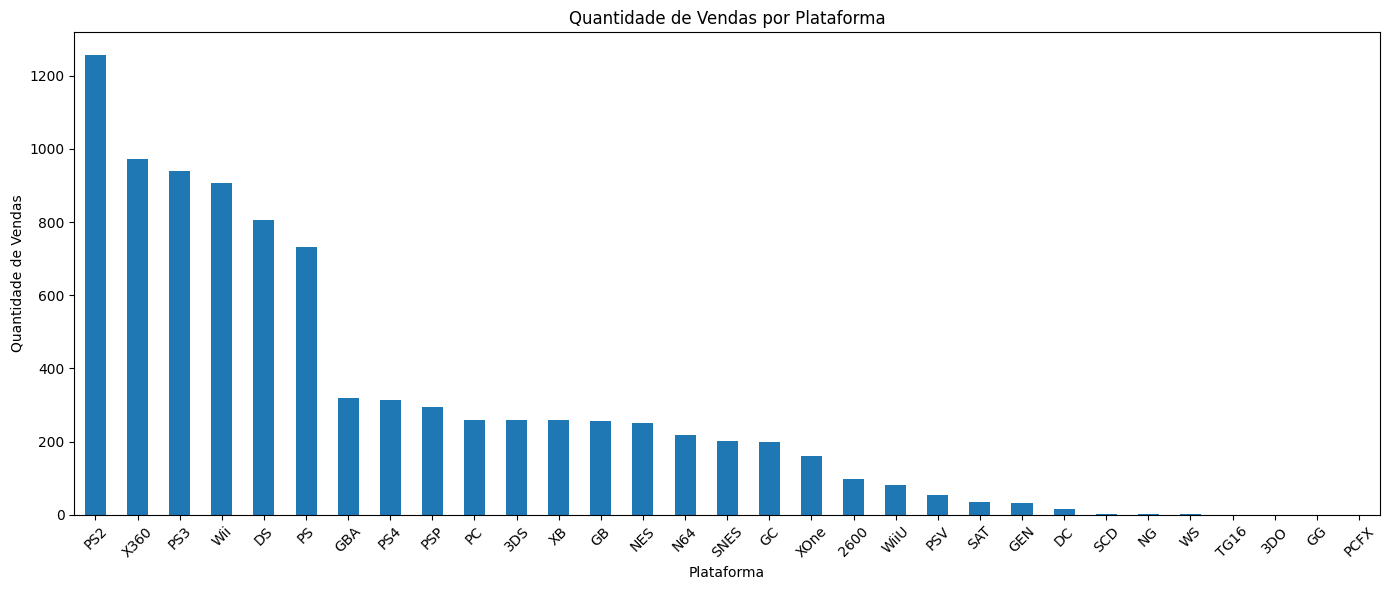

In [8]:
#Maiores plataformas com vendas totais.
vendas_por_plataforma = (
    games.groupby('platform')['total_sales']
    .sum()
    .sort_values(ascending=False)
    .plot(
        kind='bar',
    figsize=(14, 6))
)

plt.title('Quantidade de Vendas por Plataforma')
plt.xlabel('Plataforma')

plt.ylabel('Quantidade de Vendas')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()





# Gráficos de Vendas por Anos das Top5 Plataformas

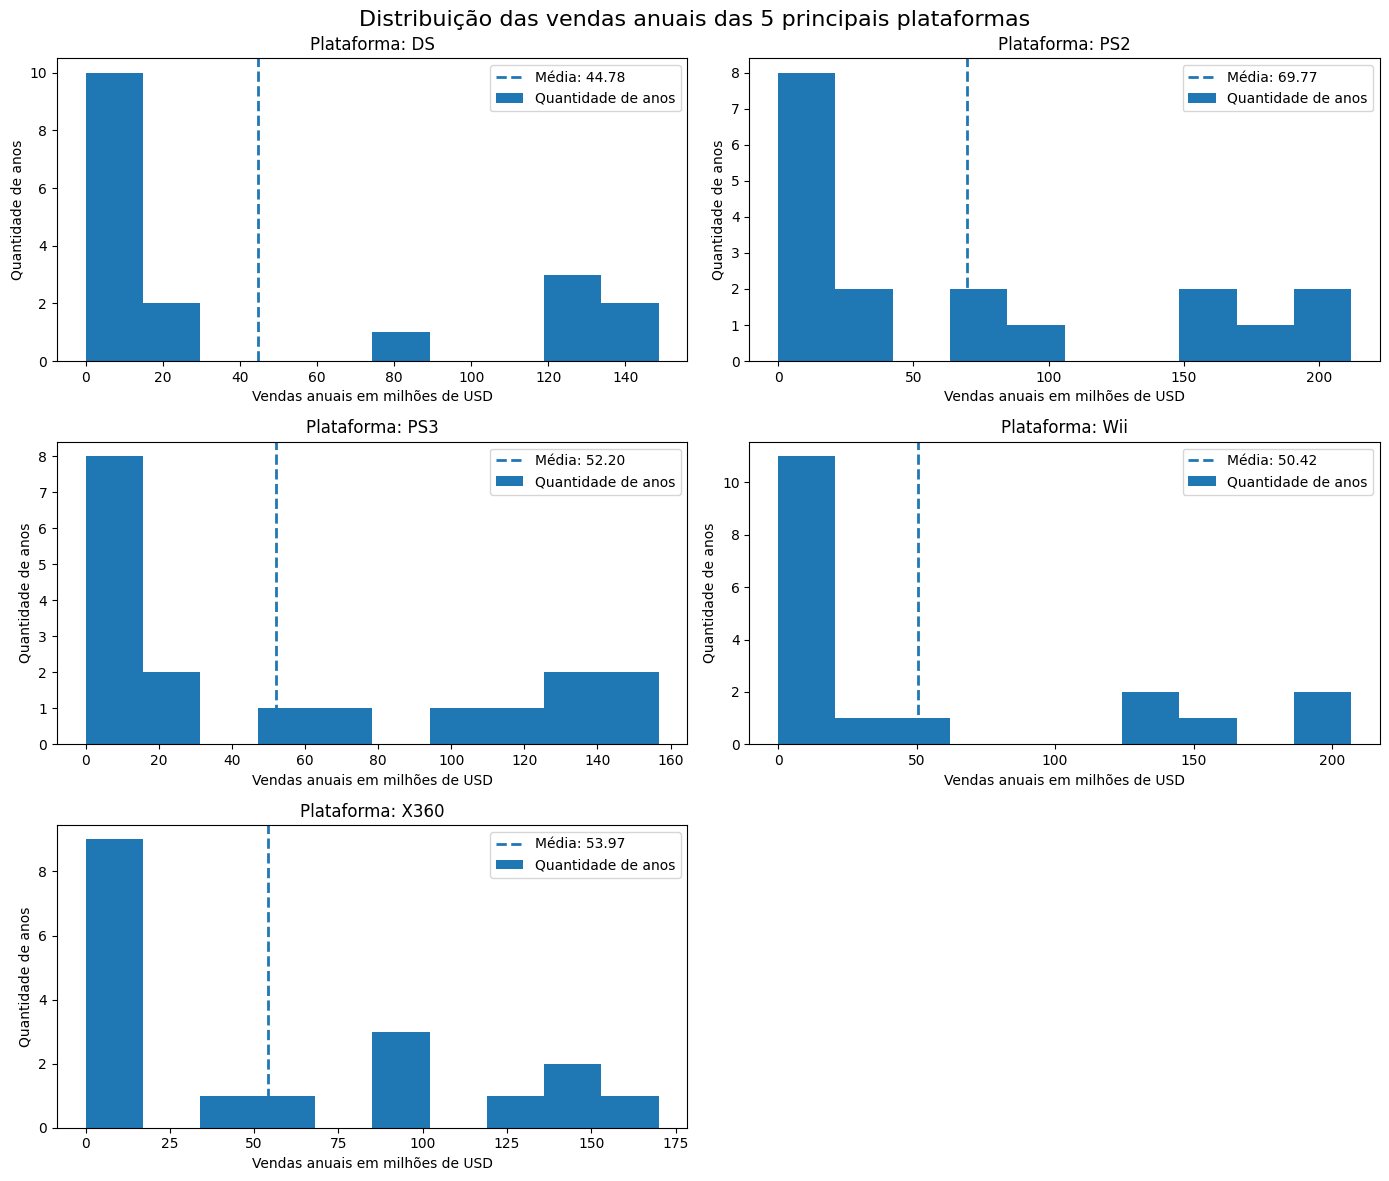

In [9]:
#Agrupar as 5 melhores Plataformas 
#Filtrar só as melhores plataformas
#Ver o total de venda por ano das 5 melhores plataformas


top_plataformas = (games.groupby('platform')['total_sales']
    .sum()
    .nlargest(5)
    .index
)                   

games_top = games[games['platform'].isin(top_plataformas)]
tempo_jogo_sair = (games_top.groupby(['year_of_release', 'platform'])['total_sales']
    .sum()
    .unstack(fill_value= 0)
)

#Gráfico de Histograma das 5 plataformas com mais venda 
distribuicao_vendas = (
    games_top
    .groupby(['year_of_release', 'platform'])['total_sales']
    .sum()
    .unstack(fill_value=0)
)

# Criando uma área com 6 espaços para os gráficos
fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(14, 12)
)

# Criando um histograma para cada plataforma
for ax, plataforma in zip(
    axes.flatten(),
    distribuicao_vendas.columns
):
    
    vendas = distribuicao_vendas[plataforma].dropna()
    media = vendas.mean()

    ax.hist(
        vendas,
        bins=10,
        label='Quantidade de anos'
    )

    ax.axvline(
        media,
        linestyle='--',
        linewidth=2,
        label=f'Média: {media:.2f}'
    )

    ax.set_title(f'Plataforma: {plataforma}')
    ax.set_xlabel('Vendas anuais em milhões de USD')
    ax.set_ylabel('Quantidade de anos')
    ax.legend()

# Removendo o espaço que ficou vazio
for ax in axes.flatten()[len(distribuicao_vendas.columns):]:
    ax.remove()

plt.suptitle(
    'Distribuição das vendas anuais das 5 principais plataformas',
    fontsize=16
)

plt.tight_layout()
plt.show()


# Periodo de tempo que plataformas levam para desaparecer e Gráficos de Plataformas que caiu a conversão.

In [10]:
#periodo de tempo leva para as novas platafromas aparecerem e as antigas desaparecem 
tempo_plataforma =(
    games.groupby('platform')['year_of_release']
    .agg(ano_inicio = 'min',
    ano_final = 'max')
    .reset_index()

)
tempo_plataforma['tempo_total']=(
    tempo_plataforma['ano_final'] - tempo_plataforma['ano_inicio'] + 1
    
)
# calculando o tempo medio e mediana de uma plataforma
ultimo_ano_base = games['year_of_release'].max()

plataformas_encerradas = tempo_plataforma[
    tempo_plataforma['ano_final'] < ultimo_ano_base
].copy()

media_duracao = plataformas_encerradas['tempo_total'].mean()
mediana_duracao = plataformas_encerradas['tempo_total'].median()

print(f'Duração média: {media_duracao:.1f} anos')
print(f'Duração mediana: {mediana_duracao:.1f} anos')




Duração média: 9.8 anos
Duração mediana: 9.0 anos


In [11]:
#Plataformas que caiu a conversão
#vendas históricas 
vendas_historicas_top5 = (
    games.groupby('platform')['total_sales']
    .sum()
    .reindex(top_plataformas)
)
#top5 vendas ultimos anos
vendas_ultimo_ano_top5 = (
    games[
        (games['year_of_release'] == ultimo_ano_base) &
        (games['platform'].isin(top_plataformas))
    ]
    .groupby('platform')['total_sales']
    .sum()
    .reindex(top_plataformas, fill_value=0)
)

# Criando uma tabela de comparação
comparacao_top5 = pd.DataFrame({
    'vendas_historicas': vendas_historicas_top5,
    'vendas_ultimo_ano': vendas_ultimo_ano_top5
})

#filtrando as que tiveram vendas altas mais zero no ultimo ano
top5_sem_vendas = comparacao_top5[
comparacao_top5['vendas_ultimo_ano'] == 0]

top5_sem_vendas

,vendas_historicas,vendas_ultimo_ano
platform,,
PS2,1255.77,0.0
DS,806.12,0.0


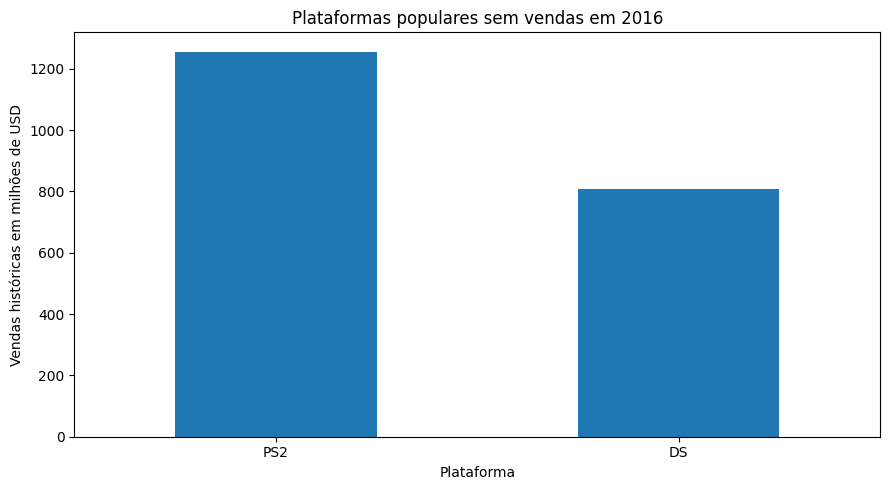

In [12]:
#grafico das plataformas sem vendas no ultimo ano 
top5_sem_vendas['vendas_historicas'].plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title(
    f'Plataformas populares sem vendas em {int(ultimo_ano_base)}'
)
plt.xlabel('Plataforma')
plt.ylabel('Vendas históricas em milhões de USD')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


##### Respostas das primeiras analises de Dados 
Apartir dos anos 2000 que as vendas de Jogos começaram aumentar nas plataformas, os jogos lançados seguiram o mesmo fluxo. Elas tiveram um pico de vendas e jogos lançados em 2008, as plataformas mais antigas não acompanharam o fluxo e acabaram diminuindo a sua venda com os anos, as plataformas tem uma media de 10 anos para desaparecer e algumas plataformas mesmo tento pico de vendas historias estão diminuindo seu numero de vendas no ultimo ano. Vou pegar as top5 plataformas para fazer a analise e os ultimos 6 anos, vou fazer a verificação dos dados de 2016 primeiros, para ver como estão os numeros numeros nele, e a qualidade dos dados.


In [13]:
#Vendo os valores de numeros nulos e games lançados em 2016 
games['year_of_release'].value_counts().sort_index().tail(6)


2011    1136
2012     653
2013     544
2014     581
2015     606
2016     502
Name: year_of_release, dtype: int64

In [14]:
games_2016 =  games[games['year_of_release'] == 2016]
games_2016.isnull().sum()

name                 0
platform             0
year_of_release      0
genre                0
na_sales             0
eu_sales             0
jp_sales             0
other_sales          0
critic_score       270
user_score         240
rating               0
total_sales          0
dtype: int64

In [15]:
#total_numeros_por ano
numeros_nulos_por_ano = (
     games['critic_score']
    .isnull()
    .groupby(games['year_of_release'])
    .sum()
)

total_jogos_ano = games['year_of_release'].value_counts()
porcentagem_nulos_por_ano = numeros_nulos_por_ano / total_jogos_ano *100
porcentagem_nulos_por_ano.tail(6)


2011    55.985915
2012    50.842266
2013    49.816176
2014    55.077453
2015    62.871287
2016    53.784861
dtype: float64

# Resultado da Analise de Dados Nulos
Como as porcentagens de Numeros Nulos não alteram muito no decorrer dos ultimos anos, mesmo o ano de 2016 tendo bastante dados Nulos,ele também tinha um numero menor de vendas,com isso igualando as porcentagems de nulos entre os anos. Com isso incluirei o ano de 2016 na ánalise.

In [16]:
#analisando os ultimos anos de vendas 
periodo_recente = games[
    games['year_of_release'] >= 2011
]
periodo_recente

vendas_recentes = (
    periodo_recente
    .groupby('platform')['total_sales']
    .sum()
    .sort_values(ascending=False)
)

vendas_recentes

platform
PS3     445.57
X360    380.38
PS4     314.14
3DS     257.81
XOne    159.32
PC       97.68
Wii      95.02
WiiU     82.19
PSV      53.81
DS       38.73
PSP      29.01
PS2       0.45
Name: total_sales, dtype: float64

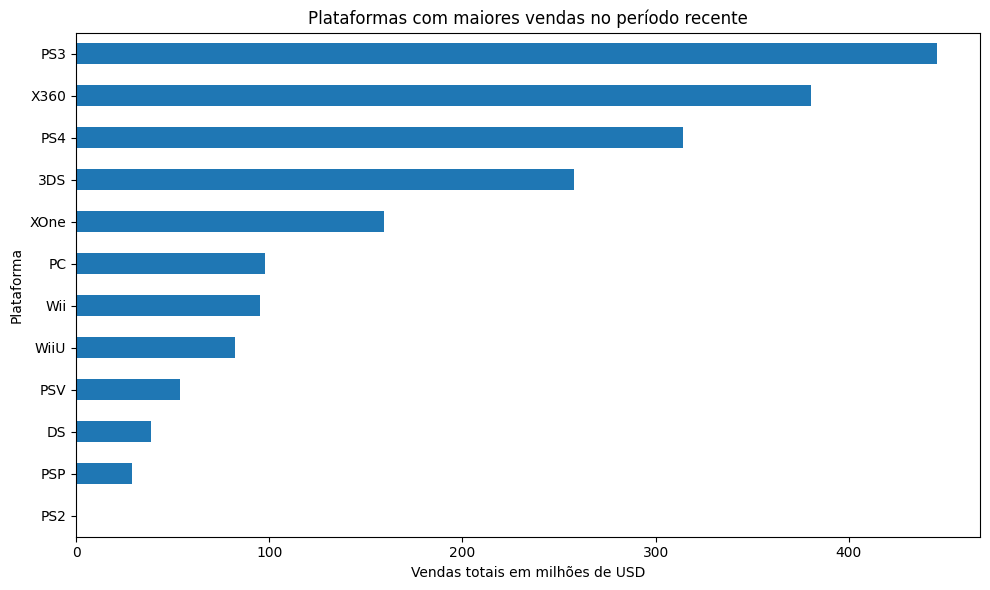

In [17]:
vendas_recentes.sort_values().plot(
    kind='barh',
    figsize=(10, 6)
)

plt.title('Plataformas com maiores vendas no período recente')
plt.xlabel('Vendas totais em milhões de USD')
plt.ylabel('Plataforma')
plt.tight_layout()
plt.show()

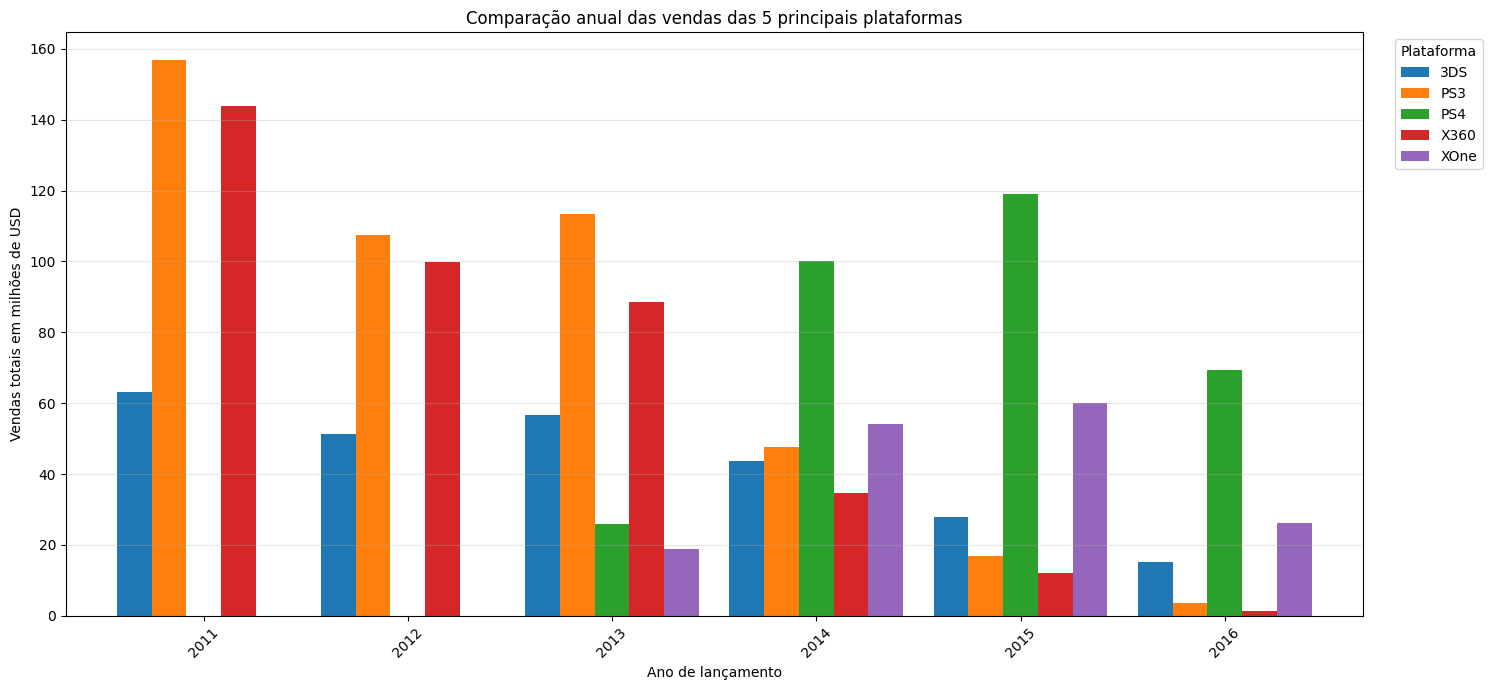

In [18]:
# Analise de Aumento ou Queda das Vendas nos anos 
#vendo as plataformas que mais venderam 
top_5_recentes = vendas_recentes.head(5).index

dados_top_5 = periodo_recente[
    periodo_recente['platform'].isin(top_5_recentes)
]

#grafico agrupado de barras para ver todas as melhores plataformas em vendas por ano
vendas_anuais =( 
    dados_top_5.groupby(['year_of_release', 'platform'])['total_sales']
        .sum()
        .unstack(fill_value=0)
        .sort_index()
)
ax = vendas_anuais.plot(kind='bar',
    stacked=False,
    figsize=(15, 7),
    width=0.85
)

plt.title('Comparação anual das vendas das 5 principais plataformas')
plt.xlabel('Ano de lançamento')
plt.ylabel('Vendas totais em milhões de USD')

plt.legend(
    title='Plataforma',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()





# Resultados da Ánalise nas vendas de plataformas durante os anos 
Mesmo tempo vendas históricas em alguns anos a plataforma de ps2 está em
alto ritmo de queda chegando a não ter venda no ultimo ano,
como as plataformas levam em torno de 9 anos para aparecer ou desaparecer,
escolhi os dados dos ultimos 6 anos. Aonde algumas das plataformas antigas desaparecerem 
deram formas para as plataformas mais moderna como o PS4 que foi lançado em 2013 e vem crescendo
no mercado. Levando em vista as plataformas com mais tempo em mercado e vendas a 3DS se manteve 
por alguns anos com o seu resultado e caindo um pouco no ultimo ano.
 
Mesmo o ps3 tendo um nivel de venda muito alto com o tempo as vendas deles vieram ter uma queda, desde 2014 suas vendas estão em quedas enquanto o ps4 mesmo sendo o terceiro em vendas ele vem conseguindo aumentar suas vendas ano a ano no ano de lançamento de 2013 ele aumentou de 20 milhões a 80 milhões no ultimo ano, levando em conta que os dados podem não estarem completos . X360 mesmo sendo o segundo com maior vendas desde o seu lançamento vem diminuindo as suas vendas sendo ultrapasso em vendas pelo XOne que foi lançado em 2013.

Vou escolher as plataformas PS4 E XOne por que ambas foram lançadas no mesmo ano 2013 e estão em crescimento constantes, elas são substitutas das gerações anteriores ps3 e x360 por isso a tendencia das vendas é aumentar, por serem o produto mais novo em geração do mercado 






# Gráfico de caixas para a analise das duas Plataformas escolhidas


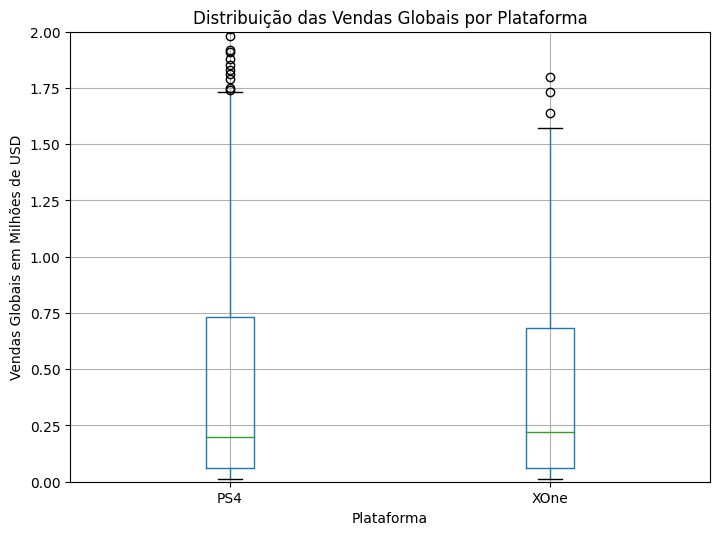

In [19]:
#escolhendo as duas plataformas 
plataformas_escolhidas = games[
    games['platform'].isin(['PS4', 'XOne'])
]

plataformas_escolhidas.boxplot(
    column='total_sales',
    by='platform',
    figsize=(8, 6)
)

plt.title('Distribuição das Vendas Globais por Plataforma')
plt.suptitle('')
plt.xlabel('Plataforma')
plt.ylabel('Vendas Globais em Milhões de USD')
plt.ylim(0, 2)
plt.show()

In [20]:
plataformas_escolhidas.groupby(
    'platform'
)['total_sales'].describe()

,count,mean,std,min,25%,50%,75%,max
platform,,,,,,,,
PS4,392.0,0.801378,1.609456,0.01,0.06,0.20,0.730,14.63
XOne,247.0,0.645020,1.036139,0.01,0.06,0.22,0.685,7.39


# Descrevendo a Ánalise 
As médias e medianas deram uma grande diferença, mas levei em conta o ano
de 2015 no ps4 que deu uma onda de vendas bem grandes, fazendo assim subir 
a media da plataforma, que é a plataforma que apresenta mais outliers. 
Já na XOne tivemos alguns valores atipicos que pode ter sido no ano de 2015 aonde 
teve um aumento nas vendas também.
# Escolhendo a platafroma ps4 para a correlação entre avaliações e vendas

In [21]:
#separando apenas a plataforma PS4
games_ps4 = games[
    games['platform'] == 'PS4'
].copy()

#separando as colunas 

critic_ps4 = games_ps4[['critic_score' ,'total_sales' ]].dropna()
user_criticps4 = games_ps4[['user_score','total_sales']].dropna() 

print('Jogos com avaliações de criticos', len(critic_ps4))
print('Jogos com avaliações de usuários', len(user_criticps4))

Jogos com avaliações de criticos 252
Jogos com avaliações de usuários 257


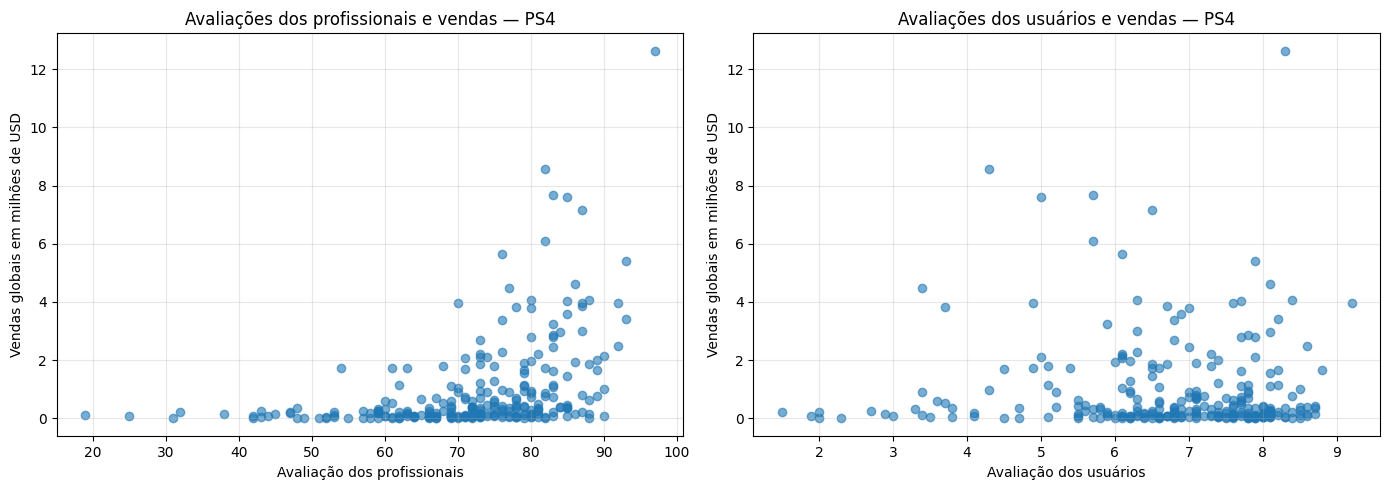

In [22]:
#grafico de de dispersão e correlação 

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14, 5)
)

# Avaliações dos profissionais
axes[0].scatter(
    critic_ps4['critic_score'],
    critic_ps4['total_sales'],
    alpha=0.6
)

axes[0].set_title('Avaliações dos profissionais e vendas — PS4')
axes[0].set_xlabel('Avaliação dos profissionais')
axes[0].set_ylabel('Vendas globais em milhões de USD')
axes[0].grid(alpha=0.3)

# Avaliações dos usuários
axes[1].scatter(
    user_criticps4['user_score'],
    user_criticps4['total_sales'],
    alpha=0.6
)

axes[1].set_title('Avaliações dos usuários e vendas — PS4')
axes[1].set_xlabel('Avaliação dos usuários')
axes[1].set_ylabel('Vendas globais em milhões de USD')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [23]:
#correlação 
correlação_criticos = critic_ps4 [
    'critic_score'
].corr(critic_ps4['total_sales'])

correlação_usuarios = user_criticps4 [
    'user_score'
].corr(user_criticps4['total_sales'])

print(f'Correlação entre as avaliações dos criticos e vendas:', f'{correlação_criticos:.2f}')
print(f'Correlação entre as avaliações dos usuários e vendas:', f'{correlação_usuarios:.2f}')


Correlação entre as avaliações dos criticos e vendas: 0.41
Correlação entre as avaliações dos usuários e vendas: -0.03


# Resposta na Analise de correlação 
A correlação de usuários e vendas de plataformas deu negativa, seguindo na mesma conclusão que o gráfico de dispersão ele segue sem nenhum padrão e disperso, seguindo o resultado que a avaliação dos usuários não interfere nos resultados das vendas de plataforma. 
Já na avaliação dos criticos temos uma leve tendencia de subida na diagonal com isso revelando uma correlação moderada de 0.41 na influências dos criticos com as vendas nas plataformas

In [24]:
#criando distribuição por generos 
generos_base = periodo_recente.dropna(subset= ['genre']).copy()

#tabela por generos
tabela_generos = (
    generos_base
    .groupby('genre')
    .agg(quantidade_jogos =('total_sales', 'size'),
         vendas_total = ('total_sales','sum'),
         media_jogo = ('total_sales', 'mean'),
         mediana_jogo= ('total_sales', 'median'))
    .sort_values('vendas_total', ascending = False)
)
tabela_generos

,quantidade_jogos,vendas_total,media_jogo,mediana_jogo
genre,,,,
Action,1269,557.80,0.439559,0.130
Shooter,329,402.91,1.224650,0.410
Role-Playing,465,245.63,0.528237,0.150
Sports,389,237.15,0.609640,0.200
Misc,375,139.42,0.371787,0.130
Platform,122,88.68,0.726885,0.185
Racing,180,88.31,0.490611,0.160
Fighting,159,66.90,0.420755,0.180
Simulation,136,50.26,0.369559,0.110


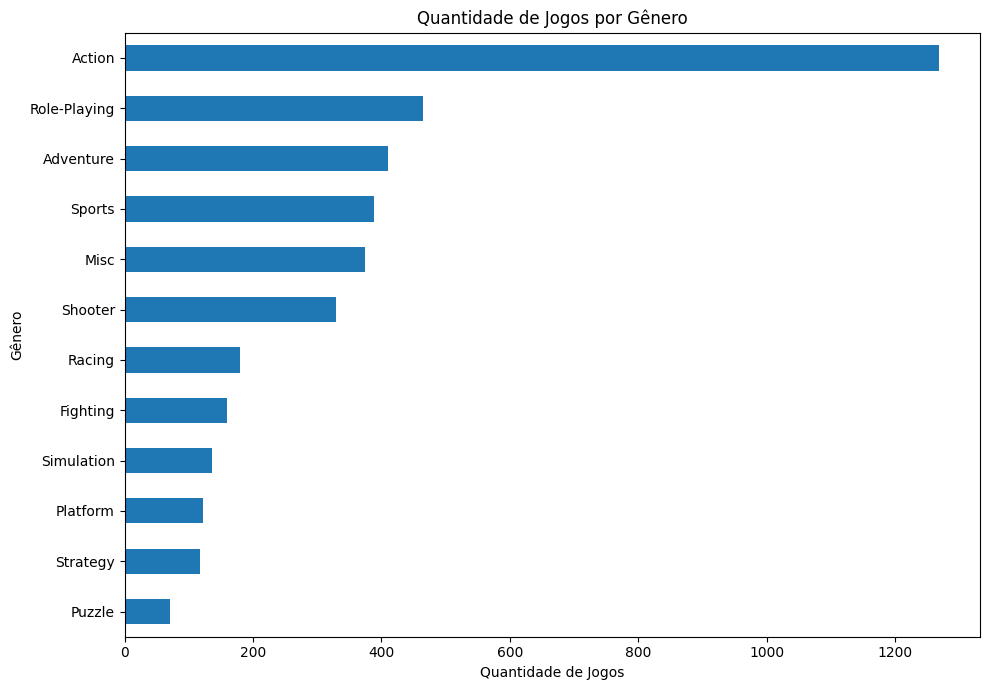

In [25]:
#grafico comparação de jogos lançados 

tabela_generos['quantidade_jogos'].sort_values().plot(
    kind='barh',
    figsize=(10, 7)
)

plt.title('Quantidade de Jogos por Gênero')
plt.xlabel('Quantidade de Jogos')
plt.ylabel('Gênero')
plt.tight_layout()
plt.show()

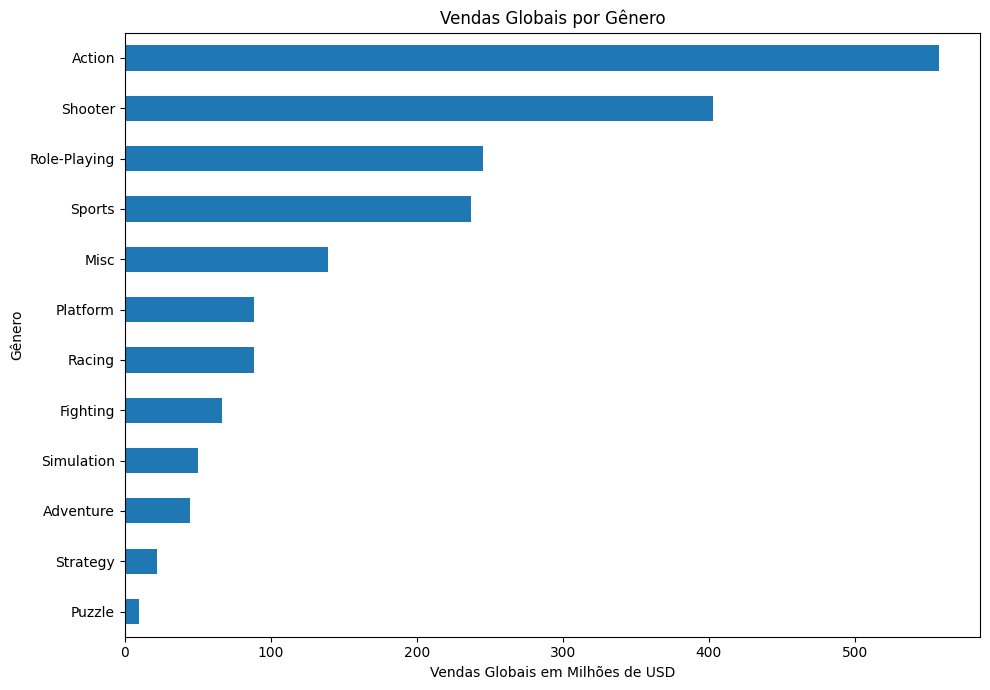

In [26]:
#comparação de vendas
tabela_generos['vendas_total'].sort_values().plot(
    kind='barh',
    figsize=(10, 7)
)

plt.title('Vendas Globais por Gênero')
plt.xlabel('Vendas Globais em Milhões de USD')
plt.ylabel('Gênero')
plt.tight_layout()
plt.show()

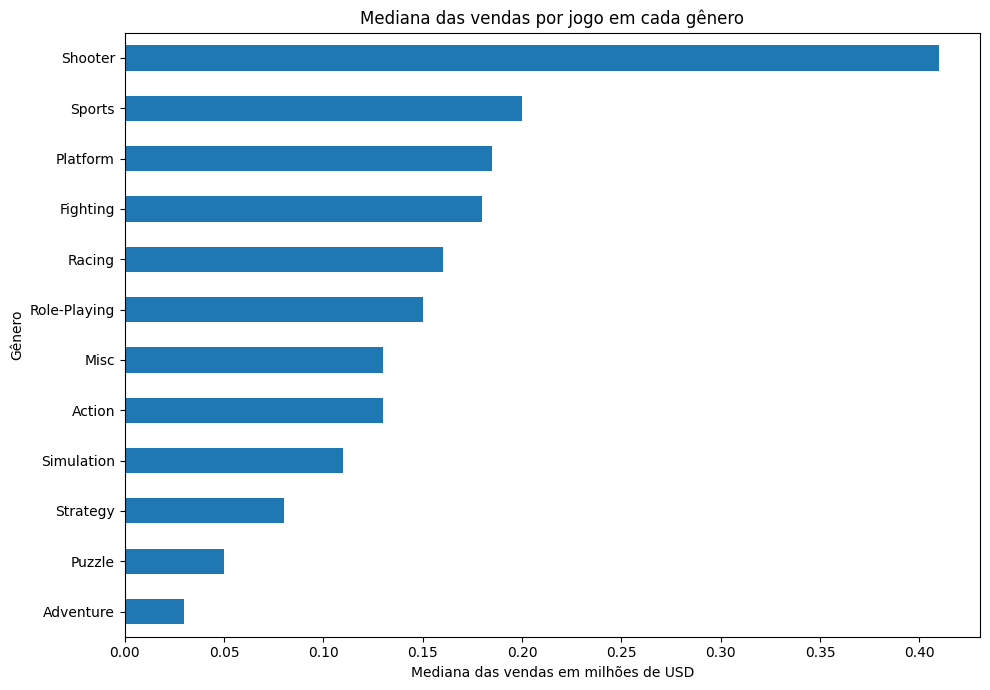

In [27]:
#mediana de vendas por jogos 
tabela_generos['mediana_jogo'].sort_values().plot(
    kind='barh',
    figsize=(10, 7)
)

plt.title('Mediana das vendas por jogo em cada gênero')
plt.xlabel('Mediana das vendas em milhões de USD')
plt.ylabel('Gênero')
plt.tight_layout()
plt.show()


# Resultado da ánalise de vendas por gêneros de jogos.
Mesmo o genero Action sendo o mais fábricado e o mais vendido no mercado , ele tem umas das piores 
medianas. Ou seja ele tem uma boa fábricação mas as suas vendas não tem um bom lucro, isso pode ser 
devido ao grande numero de jogos lançados também.  Já o shooter com um baixo numero de jogos lançados 
ele consegue ter o maior mediana, mostrando um bom nivel de vendas de jogos. Isso representa que uma 
grande quantidade de jogos não garante necessariamente uma grandes vendas por titulo. Os genêros Puzzy,Strategy e Adventure continuam tendo os piores resultados nos ultimos tempos.

# Criando um perfil de usuário para a Região AN, UE, JP.
Criando analise do perfil de cada usário, para ver o comportamento por região nas compras de jogos.

In [28]:
#criando perfil de usuário de cada região 
base_perfil = periodo_recente.copy()

#vendas da região de AN
vendas_an = (
    base_perfil
        .groupby('platform')['na_sales']
        .sum()
        .sort_values(ascending=False)
)
#calcular a quota do mercado
quota_an = (
    vendas_an / vendas_an.sum()*100
)
#criando as top 5 
top5_plataformas_an = pd.DataFrame({
    'vendas': vendas_an,
    'quota_mercado_%': quota_an
}).head(5)

top5_plataformas_an

,vendas,quota_mercado_%
platform,,
X360,226.80,27.333205
PS3,168.26,20.278153
PS4,108.74,13.104994
XOne,93.12,11.222522
3DS,82.65,9.960712


In [29]:
#perfil do usuario UE
vendas_ue = (
    base_perfil
    .groupby('platform')['eu_sales']
    .sum()
    .sort_values(ascending= False)
)
quota_ue = (
    vendas_ue / vendas_ue.sum() * 100
)
#criando as top5
top5_plataformas_ue = pd.DataFrame({
    'vendas': vendas_ue,
    'quota_mercado_%': quota_ue
}).head(5)

top5_plataformas_ue

,vendas,quota_mercado_%
platform,,
PS3,163.10,24.350916
PS4,141.09,21.064811
X360,117.10,17.483092
3DS,61.27,9.147643
PC,56.70,8.465340


In [30]:
#perfil de usuário JP
vendas_jp = (
    base_perfil
    .groupby('platform')['jp_sales']
    .sum()
    .sort_values(ascending=False)
)

quota_jp = (
    vendas_jp / vendas_jp.sum() * 100
)
top5_plataformas_jp = pd.DataFrame({
    'vendas': vendas_jp,
    'quota_mercado_%': quota_jp
}).head(5)

top5_plataformas_jp

,vendas,quota_mercado_%
platform,,
3DS,100.62,40.960716
PS3,49.39,20.105842
PSP,24.04,9.786281
PSV,21.84,8.890698
PS4,15.96,6.497049


In [31]:
#comparação das top_5 plataformas em cada região
comparacao_plataformas = pd.concat(
    [
        top5_plataformas_an['quota_mercado_%'].rename('AN'),
        top5_plataformas_ue['quota_mercado_%'].rename('UE'),
        top5_plataformas_jp['quota_mercado_%'].rename('JP')
    ],
    axis=1
).fillna(0)

comparacao_plataformas.round(2)

,AN,UE,JP
platform,,,
X360,27.33,17.48,0.00
PS3,20.28,24.35,20.11
PS4,13.10,21.06,6.50
XOne,11.22,0.00,0.00
3DS,9.96,9.15,40.96
PC,0.00,8.47,0.00
PSP,0.00,0.00,9.79
PSV,0.00,0.00,8.89


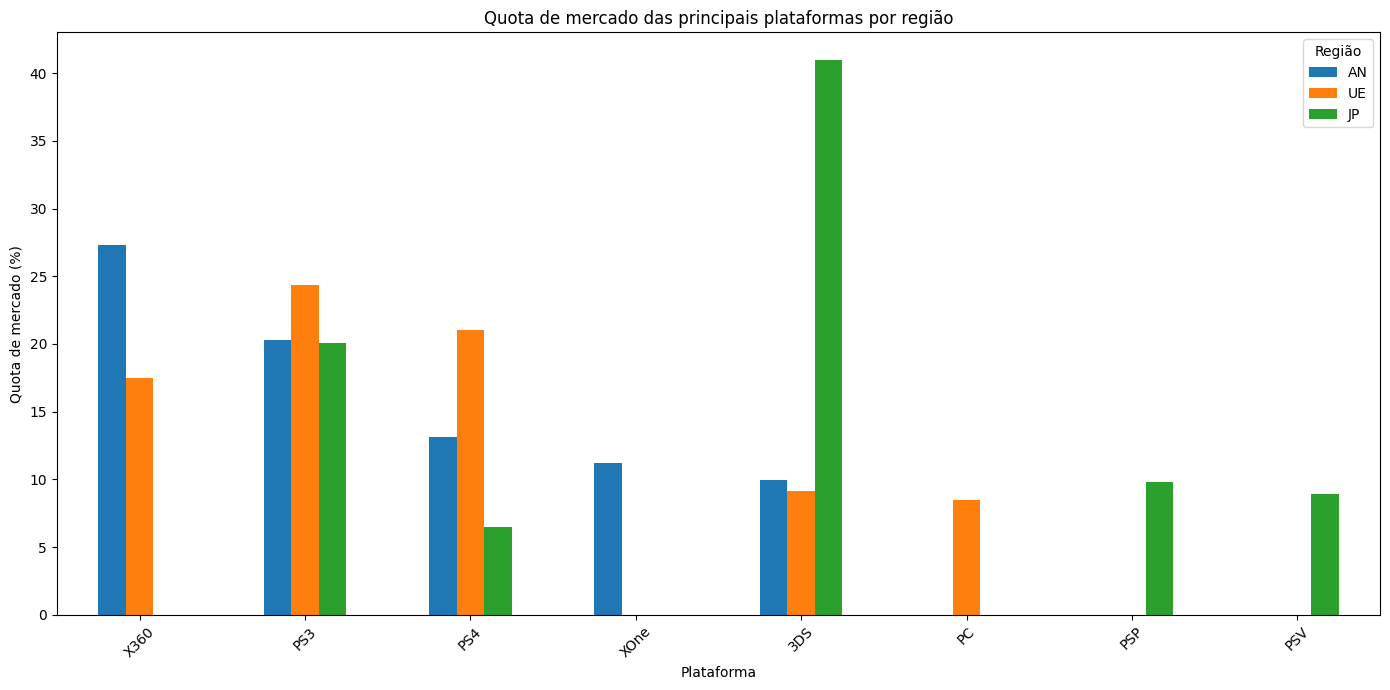

In [32]:
#grafico das top_5 plataforma em cada região 

comparacao_plataformas.plot(
    kind='bar',
    figsize=(14, 7)
)

plt.title('Quota de mercado das principais plataformas por região')
plt.xlabel('Plataforma')
plt.ylabel('Quota de mercado (%)')
plt.legend(title='Região')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Ánalise de Usuário em cada região 
Os perfis de usuários na America do Norte e a na Europa tem uma participão % de vendas muito proxima em algumas Plataformas como o ps3 . Mesmo a América do norte com maior nivel de venda no x360 ela ainda tem um numero de venda alto na plataforma do PS3 e PS4, com esse mesmo perfil os usuários da Europa compram a plataforma x360 mas o maior numero de vendas de plataforma no mercado europeu é no ps3 logo após o ps4. Já no mercado Japones o maior numero de vendas de plataforma está no 3DS e logo após no PS3, igualando o numero de vendas com a América do Norte. O perfil de usuários do Japão pode ser diferente pela diferença de consoles japones vs ocidental, com os usuários japones tendo preferencias por plataformas fabricadas por eles, sendo muito mais conhecida na sua região. Levando em conta isso, conseguimos entender por que as plataformas X360 e Xone não tem vendas no Japão. Pela preferencia nas plataformas feitas na sua região.


# Ánalise das 5 principais plataformas em cada região 


In [33]:

# principais generos AN
vendas_generos_an =(
    base_perfil
    .groupby('genre')['na_sales']
    .sum()
    .sort_values(ascending=False)
)
#quota generos AN
quota_generos_an = (
    vendas_generos_an / vendas_generos_an.sum()
    *100
)

top5_generos_an = pd.DataFrame({
    'vendas': vendas_generos_an,
    'quota_mercado_%': quota_generos_an
}).head(5)
top5_generos_an


,vendas,quota_mercado_%
genre,,
Action,230.92,27.829734
Shooter,194.43,23.432077
Sports,108.70,13.100174
Role-Playing,83.78,10.096895
Misc,69.69,8.398814


In [34]:
# principais generos UE
vendas_generos_ue =(
    base_perfil
    .groupby('genre')['eu_sales']
    .sum()
    .sort_values(ascending=False)
)
#quota generos UE
quota_generos_ue = (
    vendas_generos_ue / vendas_generos_ue.sum()
    *100
)

top5_generos_ue = pd.DataFrame({
    'vendas': vendas_generos_ue,
    'quota_mercado_%': quota_generos_ue
}).head(5)
top5_generos_ue


,vendas,quota_mercado_%
genre,,
Action,199.12,29.728721
Shooter,148.02,22.099464
Sports,88.48,13.210111
Role-Playing,62.30,9.301423
Racing,40.58,6.058615


In [35]:
# principais generos AN
vendas_generos_jp =(
    base_perfil
    .groupby('genre')['jp_sales']
    .sum()
    .sort_values(ascending=False)
)
#quota generos AN
quota_generos_jp = (
    vendas_generos_jp / vendas_generos_jp.sum()
    *100
)

top5_generos_jp = pd.DataFrame({
    'vendas': vendas_generos_jp,
    'quota_mercado_%': quota_generos_jp
}).head(5)
top5_generos_jp


,vendas,quota_mercado_%
genre,,
Role-Playing,79.87,32.513739
Action,63.62,25.898636
Misc,17.60,7.164665
Fighting,12.38,5.039691
Platform,12.13,4.937920


In [36]:
# comparação dos generos 
comparacao_generos = pd.concat(
    [
        top5_generos_an['quota_mercado_%'].rename('AN'),
        top5_generos_ue['quota_mercado_%'].rename('UE'),
        top5_generos_jp['quota_mercado_%'].rename('JP')
    ],
    axis=1
).fillna(0)

comparacao_generos.round(2)

,AN,UE,JP
genre,,,
Action,27.83,29.73,25.90
Shooter,23.43,22.10,0.00
Sports,13.10,13.21,0.00
Role-Playing,10.10,9.30,32.51
Misc,8.40,0.00,7.16
Racing,0.00,6.06,0.00
Fighting,0.00,0.00,5.04
Platform,0.00,0.00,4.94


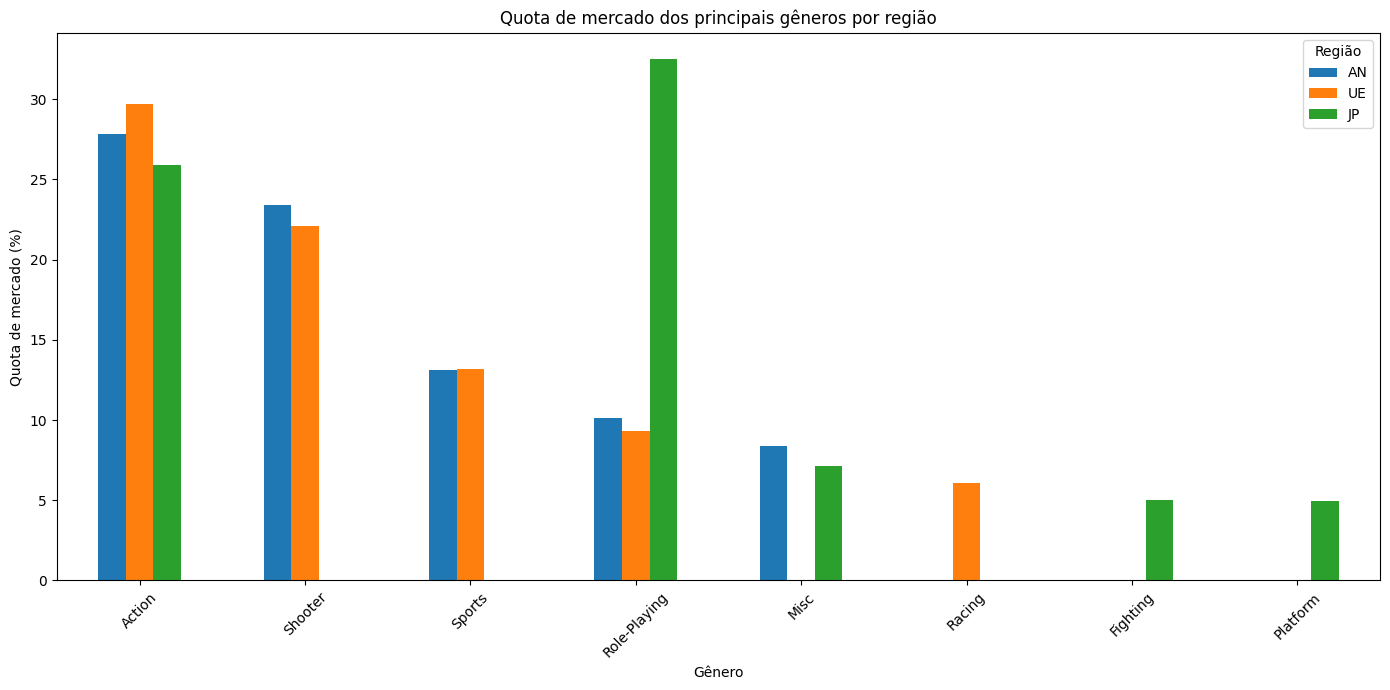

In [37]:
#grafico comparação 
comparacao_generos.plot(
    kind='bar',
    figsize=(14, 7)
)

plt.title('Quota de mercado dos principais gêneros por região')
plt.xlabel('Gênero')
plt.ylabel('Quota de mercado (%)')
plt.legend(title='Região')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Analise dos 5 principais generos nas Regiões. 
Na regiões de America do Norte e da Europa tendem as maiores vendas de jogos no genereço de ação,shooter(tiros) e sports  podendo se observar que os usuários dessas duas regiões tem comportamento muito parecidos em compra de jogos pode se ocorrer pela presença fortes de franquias ocidentais de ação, tiro e esportes e esses jogos podem ter pardida online, podendo aumentar a sua seu alcance nessas regiões. Já o Japão tem um perfil diferente das outras regiões com um numero bem elevados em generos de role-playing pode estar relacionado a forte tradição do jogos no País, elas podem lembrar um pouco a estrutura e narrativa de um anime que é muito forte no país. Um unico genero tem quota de venda parecido em todas as 3 regiões que é os de ações. Os jogos de shooter não aparecem no Japão por que conforme as suas regras, não podem ser comercializados jogos nesse conceito.


# ESRB X VENDAS EM REGIÕES INDIVIDUAIS 
 ANALISE DAS CLASSIFICAÇÕES DE CADA REGIÃO PARA VER O QUANTO AFETA NAS VENDAS.

In [38]:
#REMOVENDO OS VALORES AUSENTES DA COLUNA 
base_perfil['rating'] = (
    base_perfil['rating']
    .fillna('unknown')
)

#somando as vendas por classificação 
verbas_esbr = (
    base_perfil
    .groupby('rating')['eu_sales','na_sales', 'jp_sales']
    .sum()
)
verbas_esbr


,eu_sales,na_sales,jp_sales
rating,,,
E,141.73,170.17,36.68
E10+,78.00,117.72,11.23
EC,0.00,0.42,0.00
M,250.26,308.45,26.14
RP,0.03,0.00,0.00
T,83.16,109.31,33.39
unknown,116.61,123.69,138.21


In [39]:
#transformando as vendas em %
quota_esbr =(
    verbas_esbr
    .div (verbas_esbr.sum(axis=0),axis=1)
    *100
)
quota_esbr.round(2)

,eu_sales,na_sales,jp_sales
rating,,,
E,21.16,20.51,14.93
E10+,11.65,14.19,4.57
EC,0.00,0.05,0.00
M,37.36,37.17,10.64
RP,0.00,0.00,0.00
T,12.42,13.17,13.59
unknown,17.41,14.91,56.26


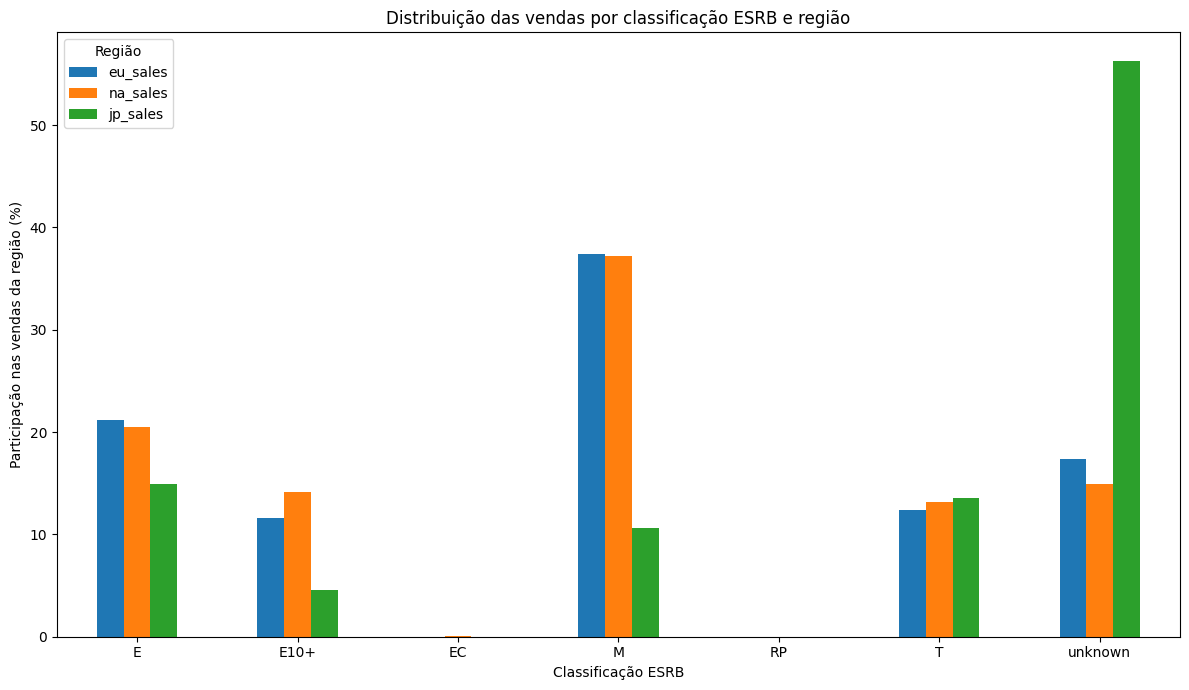

In [40]:
#gráfico de cada região 
quota_esbr.plot(
    kind='bar',
    figsize=(12, 7)
)

plt.title('Distribuição das vendas por classificação ESRB e região')
plt.xlabel('Classificação ESRB')
plt.ylabel('Participação nas vendas da região (%)')
plt.legend(title='Região')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Ánalise ESRB
As classificações ESRB afetam as vendas em algumas regiões na região da Europa e da America do norte a classificação M que seria de adultos elas tem o maior numero de vendas, já no Japão a classificação unknown ou seja sem idade definica concentra o maior numero de vendas, com isso não podemos deduzir a idade de maior consumo de plataformas no Japão, como conseguimos ver na Europa e na américa do norte. Mas uma vez elevando o comportamento diferente do povo oriental do ocidental.

# TESTES DE HIPÓTESES 
— As classificações médias dos usuários das plataformas Xbox One e PC são as mesmas.

— As classificações médias de usuários para os gêneros Action (ação) e Sports (esportes) são diferentes.

# Hipotese 1- 
As classificações médias dos usuários das plataformas Xbox One e PC são as mesma.

<b>H₀</b>: A receita média das plataformas Xbox One e PC são iguais

<b>H₁</b>: A receita média das plataformas Xbox One e PC são diferentes




In [43]:

#separando as avaliações 
#aplicando o testt e levene
avaliacoes_xone = (
    base_perfil
    .loc[
        base_perfil['platform'] == 'XOne',
        'user_score'
    ]
    .dropna()
)

avaliacoes_pc = (
    base_perfil
    .loc[
        base_perfil['platform'] == 'PC',
        'user_score'
    ]
    .dropna()
)

alpha= 0.05

stat_levene, p_levene = levene(avaliacoes_xone, avaliacoes_pc)
print(f'Estatística de Levene: {stat_levene:.3f}, p-valor: {p_levene:.3f}')

if p_levene < 0.05:
    print("As variâncias são diferentes (usar equal_var=False no teste t).")
    equal_var = False
else:
    print("Não há evidências de variâncias diferentes (usar equal_var=True no teste t).")
    equal_var = True
    
print()

t_stat, p_val = ttest_ind(avaliacoes_xone, avaliacoes_pc, equal_var=equal_var)

print(f"Resultados do Teste:")
print(f"t = {t_stat:.3f}, p-valor = {p_val:.3f}")

print(f"Média Avaliações Plataforma XOnE = {avaliacoes_xone.mean():.2f}, Média Avaliações Plataforma PC = {avaliacoes_pc.mean():.2f}")

if p_val < alpha:
    print('Rejeitamos a hipótese nula e concluímos que a média entre as plataformas são diferentes')
else:
    print('Não há evidência suficiente para afirmar que a média entre as plataformas são diferentes')


Estatística de Levene: 5.516, p-valor: 0.019
As variâncias são diferentes (usar equal_var=False no teste t).

Resultados do Teste:
t = 0.506, p-valor = 0.613
Média Avaliações Plataforma XOnE = 6.52, Média Avaliações Plataforma PC = 6.45
Não há evidência suficiente para afirmar que a média entre as plataformas são diferentes




# Hipotese 3-
As classificações médias dos usuários das dos generos Action e Sports são os mesmos.

H₀: A classificação média dos usuários dos generos Action e Sports são iguais

H₁: A classificação média dos usuários dos generos Action e Sports são diferentes.

In [44]:
#separando as avaliações 
#aplicando o testt e levene
generos_Action = (
    base_perfil
    .loc[
        base_perfil['genre'] == 'Action',
        'user_score'
    ]
    .dropna()
)

generos_Sports = (
    base_perfil
    .loc[
        base_perfil['genre'] == 'Action',
        'user_score'
    ]
    .dropna()
)

alpha= 0.05

stat_levene, p_levene = levene(generos_Action, generos_Sports)
print(f'Estatística de Levene: {stat_levene:.3f}, p-valor: {p_levene:.3f}')

if p_levene < 0.05:
    print("As variâncias são diferentes (usar equal_var=False no teste t).")
    equal_var = False
else:
    print("Não há evidências de variâncias diferentes (usar equal_var=True no teste t).")
    equal_var = True
    
print()

t_stat, p_val = ttest_ind(generos_Action, generos_Sports, equal_var=equal_var)

print(f"Resultados do Teste:")
print(f"t = {t_stat:.3f}, p-valor = {p_val:.3f}")

print(f"Média Avaliações Plataforma XOnE = {generos_Action.mean():.2f}, Média Avaliações Plataforma PC = {generos_Sports.mean():.2f}")

if p_val < alpha:
    print('Rejeitamos a hipótese nula e concluímos que a média dos usuários dos generos Action e Sports são diferentes')
else:
    print('Não há evidência suficiente para afirmar que a média entre os usuários dos generos Action e Sports são diferentes')


Estatística de Levene: 0.000, p-valor: 1.000
Não há evidências de variâncias diferentes (usar equal_var=True no teste t).

Resultados do Teste:
t = 0.000, p-valor = 1.000
Média Avaliações Plataforma XOnE = 6.78, Média Avaliações Plataforma PC = 6.78
Não há evidência suficiente para afirmar que a média entre os usuários dos generos Action e Sports são diferentes


# CONCLUSÕES DO TESTT 
Para os dois testes a hipotese nula foi formulada considerando que a média dos dois grupos diferentes são iguais e a hipotese alternativa afirma que as médias são diferentes. Essa formulação foi escolhida porque o objetivo é verificar a existência de qualquer diferença entre os grupos, sem determinar previamente qual deles possui a maior média.

Escolhi o alpha = 0.05 que significa uma tolerancia de 5% para rejeitas a hipotese nula quando é verdadeira, escolhi esse numero de 5% por que ele é muito ultilizado em analises estátistica e fornecer um equilibrio entre rigor e risco.